# 01 · Een sensor kiezen, verbinden en uitlezen (Dragino via Antratek)

In deze les doorlopen we de complete keten van een IoT-project: van het selecteren van de geschikte hardware in een webshop tot het ontcijferen van de ruwe binaire data die de sensor via de ether verstuurt.

---

### Praktijkcasus
Een varkenshouder wil in drie afdelingen van een vleesvarkensstal elke 10 minuten de temperatuur en relatieve luchtvochtigheid meten. 
* **Eisen:** De sensoren werken op batterij en moeten minstens 5 jaar zonder onderhoud kunnen functioneren. De landbouwer wil de metingen live op een smartphone en in een dashboard kunnen aflezen.
* **Infrastructuur:** Er is geen netwerkkabel aanwezig in de stal, maar wel Wi-Fi en 4G-dekking op het erf.

We doorlopen de volgende 4 stappen:
1. Een geschikte industriële sensor selecteren in de webshop (**Antratek**, Belgische/Nederlandse distributeur van IoT-hardware).
2. De officiële **technische handleiding van de fabrikant (Dragino)** raadplegen om de installatie- en netwerkvereisten te achterhalen.
3. De **ruwe binaire payloads (bytes)** die de sensor via **LoRaWAN** verstuurt met de hand decoderen, en dit controleren met een officiële JavaScript-decoder.
4. Dezelfde sensor bekijken in zijn **NB-IoT/LTE-M** variant, waarbij we zelf het netwerkprotocol (CoAP, UDP, MQTT, TCP) en het dataformaat (hex of JSON) kiezen.

## Stap 1 · De webshop raadplegen: Antratek

Open de webpagina <https://www.antratek.be/lora/sensor-nodes/temperature-humidity> (categorie *LoRa ▸ Sensor nodes ▸ Temperatuur & vochtigheid*). Je ziet hier een overzicht van industriële LoRaWAN-sensoren, hoofdzakelijk van het merk **Dragino**, met prijzen tussen € 50 en € 300.

Klik op het model **LSN50v2-S31 – LoRaWAN Temperature & Humidity Sensor** (of de nieuwere **S31-LB**).

---

### Begrippen en specificaties in de webshop

| Specificatie | Gezochte waarde | Wikipedia-stijl uitleg & Relevantie voor het project |
|---|---|---|
| **Artikelnummer** | `LSN50v2-S31-EU868` | **EU868** verwijst naar de Europese frequentieband voor ISM-radioverkeer (868 MHz). Een Amerikaanse US915-versie is in Europa illegaal en werkt hier niet op het netwerk. |
| **Meetsensor** | *Sensirion SHT31* | Een hoogwaardige, fabrieksgewijze gekalibreerde industriële sensorchip met een hoge nauwkeurigheid (±0,2 °C, ±2 % RV). |
| **Voeding & Batterij** | *8500 mAh Li-SOCl2* | **Lithium-thionylchloride (Li-SOCl2)** is een batterijchemie met een extreem lage zelfontlading, speciaal ontworpen voor IoT-toestellen die jarenlang moeten functioneren. |
| **Sleutels & Activeringsmodus** | *OTAA (Over-The-Air Activation)* | **OTAA** is een beveiligingsprotocol waarbij het toestel bij de eerste opstart unieke cryptografische sleutels uitwisselt met de netwerkserver om zich veilig aan te melden. |
| **Prijs** | € 52,95 excl. btw | Voor 3 stalafdelingen kost de sensortak dus 3 × € 52,95 ≈ € 160. |

---

### Wat ontbreekt er nog in de keten?
Een **LoRaWAN-sensor** communiceert via radiosignalen met een bereik van meerdere kilometers, maar kan **niet rechtstreeks verbinding maken met het internet**. 
Je hebt een **LoRaWAN Gateway** nodig: een draadloze 'antenne' die de radiosignalen opvangt en via Wi-Fi, Ethernet of 4G doorstuurt naar een centrale **LoRaWAN Network Server** (zoals *The Things Network (TTN)*). 

**Alternatief zonder gateway:** De fabrikant biedt exact dezelfde sensor aan als de **S31-NB / S31-CB** (NB-IoT/LTE-M). Deze variant bevat een ingebouwde 4G-modem en een simkaart, waardoor de sensor rechtstreeks met de gsm-mast en het internet communiceert.

---

### Opdracht 1.1
Noteer voor de praktijkcasus je onderbouwde keuze (LoRaWAN of NB-IoT, -LB op batterij of -LS op zonne-energie) en som op wat je naast de drie sensoren nog moet aanschaffen of instellen.

<details>
<summary><b>Oplossing tonen</b></summary>

Een verdedigbare keuze: **3 × S31-LB (LoRaWAN, batterij)** à € 52,95 plus **één gateway** (bv. Dragino LPS8v2) die via de wifi op het erf aan het internet hangt. Verder nodig: een gratis TTN-account (netwerkserver), de decoder van Dragino, en een dashboard (Datacake of ThingsBoard hebben gratis instapniveaus). Totaal eenmalig ± € 160 sensoren + gateway, geen maandelijkse kosten.

Alternatief: **3 × S31-CB (NB-IoT/LTE-M)**, geen gateway, maar drie simkaarten met abonnement (enkele euro's per maand per sensor) en je moet een server/broker kiezen. Interessant als er geen wifi of stroom voor een gateway is, of bij maar één sensor.

-LS (zonnepaneel) is in een donkere stal zinloos; -LB (batterij) volstaat: bij 10 min interval meerdere jaren (handleiding §4).

</details>

## Stap 2 · De handleiding raadplegen: Dragino

De webshop verwijst voor de technische details naar de officiële documentatie van de fabrikant. Dragino onderhoudt een centraal documentatiecentrum:
<https://wiki.dragino.com/docs/LoRaWAN-End-Node/temperature-humidity-sensors/s31-lb/>

Elke technische handleiding van een industriële IoT-sensor kent een vaste opbouw. Dit zijn de belangrijkste secties voor de installatie en gegevensverwerking:

| Sectie in Handleiding | Titel | Wikipedia-stijl uitleg & Wat je eruit leert |
|---|---|---|
| **1.3** | Specification | Meetbereik (−40…80 °C), meetnauwkeurigheid, spanning en stroomverbruik. |
| **1.4** | Sleep mode and working mode | Legt uit dat de microcontroller 99% van de tijd in **deepsleep** (diepe slaapstand) staat en enkel ontwaakt om te meten en te zenden. Hierdoor gaat de batterij jaren mee. |
| **1.6** | BLE connection | **Bluetooth Low Energy (BLE)** maakt het mogelijk om de sensor op korte afstand draadloos in te stellen via een smartphone-app. |
| **2.2** | Quick guide to connect to LoRaWAN server (OTAA) | Stappenplan voor registratie: 1. `DevEUI` en `AppKey` opgeven in The Things Network; 2. Knop 5 sec indrukken op de sensor → groene LED licht op → **Join** gelukt! |
| **2.3** | Uplink Payload | Legt exact uit hoe de 11 binaire bytes van elke meting zijn opgebouwd. |
| **2.4** | Payload Decoder file | Bevat de broncode van de officiële JavaScript-decoder voor netwerkservers. |
| **3.0** | Configure (AT-commando's) | Tekstcommando's (zoals `AT+TDC=600`) om instellingen zoals het zendinterval via de seriële poort of bluetooth te wijzigen. |

---

### Checklist "Koopklaar voor een LoRaWAN-project"
- [ ] Juiste frequentieband gekozen (**EU868** voor Europa).
- [ ] Unieke identificatiecodes beschikbaar (**DevEUI, JoinEUI/AppEUI, AppKey** op de sticker).
- [ ] Toegang tot een **LoRaWAN Network Server** (bijv. een gratis account op The Things Network).
- [ ] Een **LoRaWAN Gateway** in bereik met een actieve internetverbinding.
- [ ] De **payload-decoder** van de fabrikant om ruwe bytes om te zetten naar getallen.
- [ ] Een eindbestemming voor de data (zoals een dashboard in Datacake of ThingsBoard, of een eigen toepassing via **MQTT** of **HTTP**).

---

### Opdracht 2.1
Zoek in **§2.2** van de handleiding op wat er precies gebeurt met de groene LED wanneer het toestel succesvol verbinding maakt met het netwerk (*join*). Zoek in **§3.3.1** het AT-commando op om het zendinterval in te stellen op 10 minuten (600 seconden).

In [1]:
# ==============================================================================
# OPDRACHT 2.1: HANDLEIDING RAADPLEGEN (JOIN LED & AT-COMMANDO)
# INSTRUCTIES & HINTS FOR DE STUDENT:
# ==============================================================================
# 1. Raadpleeg §2.2 (stap 3) van de Dragino S31-LB handleiding:
#    Wat doet de groene LED tijdens het joinen en wat gebeurt er zodra de join geslaagd is?
# 2. Raadpleeg §3.3.1 (Set Transmit Interval Time):
#    Welk AT-commando stelt het zendinterval in op 10 minuten (600 seconden)?
# ==============================================================================

# SCHRIJF HIER JE ANTWOORD / CODE:
led_gedrag_bij_join = ""  # Beschrijf wat de groene LED doet bij een geslaagde join
at_commando_10_min = ""   # Geef het exacte AT-commando om de TDC op 600s te zetten

# Un-comment om je antwoord af te drukken:
# print(f"LED-gedrag bij geslaagde Join : {led_gedrag_bij_join}")
# print(f"AT-commando voor 10 min interval: {at_commando_10_min}")


In [2]:
# ==============================================================================
# OPDRACHT 2.1: HANDLEIDING RAADPLEGEN (JOIN LED & AT-COMMANDO)
# INSTRUCTIES & HINTS FOR DE STUDENT:
# ==============================================================================
# 1. Raadpleeg §2.2 (stap 3) van de Dragino S31-LB handleiding:
#    Wat doet de groene LED tijdens het joinen en wat gebeurt er zodra de join geslaagd is?
# 2. Raadpleeg §3.3.1 (Set Transmit Interval Time):
#    Welk AT-commando stelt het zendinterval in op 10 minuten (600 seconden)?
# ==============================================================================

# SCHRIJF HIER JE ANTWOORD / CODE:
led_gedrag_bij_join = ""  # Beschrijf wat de groene LED doet bij een geslaagde join
at_commando_10_min = ""   # Geef het exacte AT-commando om de TDC op 600s te zetten

# Un-comment om je antwoord af te drukken:
# print(f"LED-gedrag bij geslaagde Join : {led_gedrag_bij_join}")
# print(f"AT-commando voor 10 min interval: {at_commando_10_min}")


<details>
<summary><b>Oplossing tonen</b></summary>

§2.2 stap 3: na het indrukken van de knop (5 s) knippert de groene led 5× snel, het toestel probeert te joinen, en **na een geslaagde join brandt de groene led 5 s continu**. Daarna begint het uplinks te sturen.

§3.3.1 *Set Transmit Interval Time*: `AT+TDC=600` (waarde in seconden; standaard 1200 = 20 min). Hetzelfde kan via een downlink vanuit TTN: `01 00 02 58` (0x000258 = 600).

</details>

## Stap 3 · De ruwe binaire payload met de hand decoderen

Om batterijvermogen en zendtijd te besparen, verstuurt een LoRaWAN-sensor **geen tekst of JSON**, maar een compacte reeks ruwe geheugenwaarden (**bytes**).

Volgens sectie **2.3.2** van de Dragino-handleiding bestaat een standaard meetbericht op **FPORT = 2** uit precies **11 bytes** (22 hexadecimale tekens):

| Byte index | Bytes 0–1 | Bytes 2–5 | Byte 6 | Bytes 7–8 | Bytes 9–10 |
|---|---|---|---|---|---|
| **Inhoud** | Batterijspanning (mV) | Unix-timestamp (s) | Alarmvlag & Modus & PA8-pin | Temperatuur (×10, signed) | Relatieve Vochtigheid (×10) |

---

### Drie digitale basisbegrippen om dit te ontcijferen:

1. **Hexadecimaal stelsel (Base-16):** Computergeheugen wordt weergegeven in hex-tekens (`0` t/m `9` en `A` t/m `F`). Eén byte bestaat uit 8 bits = 2 hexadecimale tekens (`00` t/m `FF` = 0 t/m 255 in decimaal).
2. **Big-Endian byte-volgorde:** Bij getallen die uit meerdere bytes bestaan (bijv. 2 bytes = 16 bits), staat de **meest betekenisvolle byte vooraan**. `0B45` hex = $(0x0B 	imes 256) + 0x45 = (11 	imes 256) + 69 = \mathbf{2885}$.
3. **Two's Complement (Twee-complement) voor negatieve getallen:** Om negatieve temperaturen weer te geven, wordt het hoogste bit (bit 15) gebruikt als tekenbit. Als de waarde $\ge 0x8000$ (32768) is, trek je 65536 van het geheel af: `FF3F` hex = $65343 
ightarrow 65343 - 65536 = -193 
ightarrow \mathbf{-19{,}3 \ ^\circ	ext{C}}$.

We nemen de voorbeeld-payload uit de handleiding en ontleden deze stapsgewijs in Python.

In [3]:
# De voorbeeld-payload in hexadecimale tekstvorm (11 bytes = 22 hex-karakters) uit de handleiding
payload_hex = "0B456AD703600001050197"

# Converteer de hex-tekstreeks naar een binaire bytes-object in Python
payload = bytes.fromhex(payload_hex)

print("Totaal aantal ontvangen bytes:", len(payload))
print("-" * 50)

# Druk elke byte af in hexadecimaal, decimaal en binair formaat (8 bits)
for i, b in enumerate(payload):
    print(f"Byte {i:2d}: Hex {b:02X}  = Decimaal {b:3d}  = Binair {b:08b}")

Totaal aantal ontvangen bytes: 11
--------------------------------------------------
Byte  0: Hex 0B  = Decimaal  11  = Binair 00001011
Byte  1: Hex 45  = Decimaal  69  = Binair 01000101
Byte  2: Hex 6A  = Decimaal 106  = Binair 01101010
Byte  3: Hex D7  = Decimaal 215  = Binair 11010111
Byte  4: Hex 03  = Decimaal   3  = Binair 00000011
Byte  5: Hex 60  = Decimaal  96  = Binair 01100000
Byte  6: Hex 00  = Decimaal   0  = Binair 00000000
Byte  7: Hex 01  = Decimaal   1  = Binair 00000001
Byte  8: Hex 05  = Decimaal   5  = Binair 00000101
Byte  9: Hex 01  = Decimaal   1  = Binair 00000001
Byte 10: Hex 97  = Decimaal 151  = Binair 10010111


<div style="background-color: #e8f5e9; color: #1b5e20; border-left: 5px solid #2e7d32; padding: 12px; margin: 12px 0; border-radius: 4px;">
<strong>💡 Interpretatie van de uitvoer:</strong><br>
<strong>Binaire Bytes naar Hex:</strong> De 11 ontvangen bytes worden weergegeven als 22 hexadecimale tekens. Elke byte bestaat uit 8 bits (binair, bijv. <code>00001011</code>) wat overeenkomt met een getal tussen 0 en 255 (decimaal) of twee hex-tekens (bijv. <code>0B</code>).
</div>

### 3a · Batterijspanning (Bytes 0–1)

In [4]:
# Handmatige berekening via Big-Endian gewichten: eerste byte weegt 256x zwaarder
batterij_mv = payload[0] * 256 + payload[1]

# Automatische berekening via de ingebouwde Python-functie int.from_bytes()
batterij_mv_2 = int.from_bytes(payload[0:2], byteorder="big")

# Zet millivolt (mV) om naar Volt (V) door te delen door 1000
print(f"Bytes 0-1 = {payload[0]:02X} {payload[1]:02X} -> {batterij_mv} mV = {batterij_mv/1000:.3f} V")

# Controleer of onze uitkomst exact overeenkomt met de voorbeelddocumentatie (2885 mV = 2.885 V)
assert batterij_mv == batterij_mv_2 == 2885

Bytes 0-1 = 0B 45 -> 2885 mV = 2.885 V


### 3b · Tijdstip van de meting (Bytes 2–5)

Een **Unix-timestamp** is een internationale standaard die het aantal verstreken seconden telt sinds 1 januari 1970 om 00:00:00 UTC (de *Unix Epoch*). De interne klok van de sensor wordt bij elke netwerkaanmelding automatisch gesynchroniseerd.

In [5]:
from datetime import datetime, timezone  # Importeer datum- en tijdsmodules

# Converteer de 4 bytes (32 bits) naar een 32-bit geheel getal volgens Big-Endian byte-volgorde
timestamp = int.from_bytes(payload[2:6], byteorder="big")

# Converteer het aantal seconden naar een menselijk leesbare datum en tijd in UTC
tijd_utc = datetime.fromtimestamp(timestamp, tz=timezone.utc)

print(f"Bytes 2-5 = {payload[2:6].hex().upper()} -> {timestamp} s -> {tijd_utc:%Y-%m-%d %H:%M:%S} UTC")

Bytes 2-5 = 6AD70360 -> 1792476000 s -> 2026-10-20 06:00:00 UTC


### 3c · Status- en Alarmvlaggen (Byte 6)

Om extreem zuinig om te springen met de zendtijd, bevat **één enkele byte** (8 bits) drie afzonderlijke informatie-elementen:

| Bits | Bit 7 | Bits 6–2 | Bit 1 | Bit 0 |
|---|---|---|---|---|
| **Inhoud** | Status van pin PA8 (1 = Laag) | Modus (0 = Normale meting, 31 = Antwoord op vraag) | Gereserveerd | Alarmvlag (1 = Drempelwaarde overschreden) |

We lezen afzonderlijke bits uit met behulp van **bitmaskers** (`&` bitwise EN) en **bit-verschuivingen** (`>>`).

In [6]:
vlaggen = payload[6]  # Haal de 7e byte (index 6) op

# Bit 0 insluiten met masker 0x01 (00000001 binair)
alarm = vlaggen & 0x01

# Bits 6-2 insluiten met masker 0x7C (01111100 binair) en 2 posities naar rechts schuiven
modus = (vlaggen & 0x7C) >> 2

# Bit 7 insluiten met masker 0x80 (10000000 binair) en 7 posities naar rechts schuiven
pa8 = (vlaggen & 0x80) >> 7

print(f"Byte 6 = Hex {vlaggen:02X} = Binair {vlaggen:08b}")
print("Alarmtoestand :", "JA (Drempel overschreden!)" if alarm else "Nee (Normaal)")
print("Werkmodus     :", modus, "(0 = Standaard periodieke meting)")
print("Pin PA8 status:", "Laag" if pa8 else "Hoog")

Byte 6 = Hex 00 = Binair 00000000
Alarmtoestand : Nee (Normaal)
Werkmodus     : 0 (0 = Standaard periodieke meting)
Pin PA8 status: Hoog


### 3d · Temperatuur (Bytes 7–8) — Houd rekening met het tekenbit

In [7]:
# Lees de 2 bytes (16 bits) in als een Big-Endian geheel getal
ruw = int.from_bytes(payload[7:9], byteorder="big")

# Controleer of het hoogste bit (bit 15 = 0x8000) gezet is. Zo ja, dan is het getal negatief.
if ruw & 0x8000:
    ruw -= 65536  # Trek 2^16 af om de negatieve waarde te verkrijgen (Two's Complement)

temperatuur = ruw / 10  # De waarde is door de fabrikant vermenigvuldigd met 10
print(f"Bytes 7-8 = {payload[7:9].hex().upper()} -> Ruwe waarde: {ruw} -> Temperatuur: {temperatuur} °C")

# In Python kan int.from_bytes dit ook automatisch via het argument 'signed=True':
assert int.from_bytes(payload[7:9], byteorder="big", signed=True) / 10 == temperatuur

# Test het negatieve voorbeeld uit de handleiding (Hex FF3F -> -19.3 °C)
negatief_voorbeeld = bytes.fromhex("FF3F")
temp_negatief = int.from_bytes(negatief_voorbeeld, "big", signed=True) / 10
print(f"Controle negatieve waarde FF3F -> {temp_negatief} °C")

Bytes 7-8 = 0105 -> Ruwe waarde: 261 -> Temperatuur: 26.1 °C
Controle negatieve waarde FF3F -> -19.3 °C


### 3e · Relatieve Luchtvochtigheid (Bytes 9–10)

In [8]:
# Lees de 2 bytes voor luchtvochtigheid (geen negatieve waarden mogelijk)
vochtigheid = int.from_bytes(payload[9:11], byteorder="big") / 10

print(f"Bytes 9-10 = {payload[9:11].hex().upper()} -> Relatieve Vochtigheid: {vochtigheid} % RV")

Bytes 9-10 = 0197 -> Relatieve Vochtigheid: 40.7 % RV


<div style="background-color: #e8f5e9; color: #1b5e20; border-left: 5px solid #2e7d32; padding: 12px; margin: 12px 0; border-radius: 4px;">
<strong>💡 Interpretatie van de uitvoer:</strong><br>
<strong>Relatieve Luchtvochtigheid (Bytes 9-10):</strong> Het binaire paar <code>01 97</code> vormt in Big-Endian het getal <code>407</code>. Deling door 10 geeft exact <code>40.7 % RV</code>. Omdat luchtvochtigheid nooit negatief kan zijn, is er geen tekenbit nodig.
</div>

### 3f · De volledige stappen gecombineerd in één Python-functie

Een **Payload Decoder** op een netwerkserver (zoals TTN) voert exact onderstaande logica uit: binaire bytes binnen krijgen en een overzichtelijke Python dictionary (of JSON) teruggeven.

In [9]:
def decodeer_s31lb(payload_hex: str, fport: int = 2) -> dict:
    '''
    Decodeer een hexadecimale payload van een Dragino S31-LB sensor.
    Conform sectie 2.3.2 van de officiële handleiding.
    '''
    b = bytes.fromhex(payload_hex)
    
    # Controleer of het FPORT-poortnummer en de lengte van de payload correct zijn
    if fport != 2 or len(b) != 11:
        raise ValueError("Ongeldige payload: verwacht precies 11 bytes op FPORT 2")
    
    return {
        "batterij_V":    int.from_bytes(b[0:2], "big") / 1000,
        "tijd_utc":      datetime.fromtimestamp(int.from_bytes(b[2:6], "big"), tz=timezone.utc).isoformat(),
        "alarm":         bool(b[6] & 0x01),
        "modus":         (b[6] & 0x7C) >> 2,
        "temperatuur_C": int.from_bytes(b[7:9], "big", signed=True) / 10,
        "RV_pct":        int.from_bytes(b[9:11], "big") / 10,
    }

# Test onze functie uit op de voorbeeld-payload
decodeer_s31lb(payload_hex)

{'batterij_V': 2.885,
 'tijd_utc': '2026-10-20T06:00:00+00:00',
 'alarm': False,
 'modus': 0,
 'temperatuur_C': 26.1,
 'RV_pct': 40.7}

<div style="background-color: #e8f5e9; color: #1b5e20; border-left: 5px solid #2e7d32; padding: 12px; margin: 12px 0; border-radius: 4px;">
<strong>💡 Interpretatie van de uitvoer:</strong><br>
<strong>Gestructureerde Python Dictionary:</strong> De ruwe binaire hex-string is omgezet naar een overzichtelijke Python dictionary. De waarden zijn automatisch voorzien van de juiste eenheden en datatypes: spanning in Volt (<code>2.885 V</code>), ISO-tijdstempel in UTC, een booleaanse alarmvlag (<code>False</code>), en temperatuur (<code>26.1 °C</code>).
</div>

### Opdracht 3.1 · Zelf verwerken en analyseren

Hieronder zie je drie hexadecimale payloads zoals ze binnenkomen in de netwerkconsole van The Things Network. Decodeer ze en vul de onderstaande tabel in:

| Sample | Hex Payload | Situatie |
|---|---|---|
| **A** | `0BC46AD703600000D60278` | Stalafdeling 3, standaard meting |
| **B** | `0AE6696486D800FFCE0393` | Buitensensor in de winter |
| **C** | `0B866A4671380101400320` | Stalafdeling 1, zomerperiode |

**Vragen:**
1. Wat is de gemeten temperatuur en luchtvochtigheid in elk van de 3 gevallen?
2. Welke sample bevat een actief alarm, en wat is daar de oorzaak van?
3. Welke sensor vertoont de laagste batterijspanning, en hoe verklaar je dat?

In [10]:
# ==============================================================================
# OPDRACHT 3.1: HEX-PAYLOADS AUTOMATISCH DECODEEREN
# INSTRUCTIES & HINTS FOR DE STUDENT:
# ==============================================================================
# 1. Definieer een dictionary 'monster_data' met de labels "A", "B", "C" en hun hex-payloads:
#    - "A": "0BC46AD703600000D60278" (Stalafdeling 3, standaard meting)
#    - "B": "0AE6696486D800FFCE0393" (Buitensensor in de winter)
#    - "C": "0B866A4671380101400320" (Stalafdeling 1, zomerperiode)
# 2. Doorloop de dictionary met een for-loop en roep voor elk monster 'decodeer_s31lb(hex_code)' aan.
# 3. Druk de resultaten overzichtelijk af en beantwoord de 3 vragen uit de opdrachttekst.
# ==============================================================================

# SCHRIJF HIER JE CODE:
monster_data = {
    "A": "0BC46AD703600000D60278",
    "B": "0AE6696486D800FFCE0393",
    "C": "0B866A4671380101400320"
}

# Doorloop de monsters en roep de decoderfunctie aan:
# for label, hex_code in monster_data.items():
#     resultaat = decodeer_s31lb(hex_code)
#     print(f"Sample {label}:", resultaat)


In [11]:
# Uitvoering en controle van Opdracht 3.1
monster_data = {
    "A": "0BC46AD703600000D60278",
    "B": "0AE6696486D800FFCE0393",
    "C": "0B866A4671380101400320"
}

for label, hex_code in monster_data.items():
    resultaat = decodeer_s31lb(hex_code)
    print(f"Sample {label}:", resultaat)

Sample A: {'batterij_V': 3.012, 'tijd_utc': '2026-10-20T06:00:00+00:00', 'alarm': False, 'modus': 0, 'temperatuur_C': 21.4, 'RV_pct': 63.2}
Sample B: {'batterij_V': 2.79, 'tijd_utc': '2026-01-12T05:30:00+00:00', 'alarm': False, 'modus': 0, 'temperatuur_C': -5.0, 'RV_pct': 91.5}
Sample C: {'batterij_V': 2.95, 'tijd_utc': '2026-07-02T14:10:00+00:00', 'alarm': True, 'modus': 0, 'temperatuur_C': 32.0, 'RV_pct': 80.0}


<div style="background-color: #e8f5e9; color: #1b5e20; border-left: 5px solid #2e7d32; padding: 12px; margin: 12px 0; border-radius: 4px;">
<strong>💡 Interpretatie van de uitvoer:</strong><br>
<strong>Analyse van de 3 Samples:</strong><br>• <strong>Sample A:</strong> Standaard routinemeting in afdeling 3 (21.4 °C, 63.2% RV, batterij 3.01 V, geen alarm).<br>• <strong>Sample B:</strong> Buitensensor in de winter. De temperatuur <code>FFCE</code> vormt via Two's Complement het negatieve getal <code>-5.0 °C</code>. De batterijspanning (2.79 V) ligt lager door het bekende verschijnsel dat lithiumcellen bij vrieskou tijdelijk een lagere klemspanning afgeven.<br>• <strong>Sample C:</strong> Zomerperiode met een hoge temperatuur (32.0 °C). De alarmvlag <code>alarm: True</code> is actief omdat de vooraf ingestelde temperatuurdrempel overschreden is.
</div>

<details>
<summary><b>Oplossing tonen</b></summary>

| | Batterij | Tijd (UTC) | Alarm | T (°C) | RV (%) |
|---|---|---|---|---|---|
| A | 3,012 V | 2026-10-20 06:00 | nee | 21,4 | 63,2 |
| B | 2,790 V | 2026-01-12 05:30 | nee | **−5,0** (`FFCE` = 65486 → −50) | 91,5 |
| C | 2,950 V | 2026-07-02 14:10 | **ja** (byte 6 = `01`) | 32,0 | 80,0 |

C is een alarm-uplink: de temperatuur overschrijdt de ingestelde drempel (hittestress in juli); de sensor stuurt dan onmiddellijk, buiten het normale interval. B heeft de laagste batterijspanning (2,79 V), mede omdat een Li-SOCl₂-cel bij vrieskou tijdelijk een lagere spanning geeft.

Veelgemaakte fouten: little-endian lezen (`450B` i.p.v. `0B45`), het teken vergeten bij B, de vlaggenbyte decimaal lezen, niet door 10 delen.

</details>

## Stap 3g · Controle met de officiële JavaScript-decoder van Dragino

Netwerkservers zoals The Things Network voeren payload-decoders uit in een **JavaScript-omgeving**. 
De fabrikant stelt deze broncode ter beschikking op GitHub:
<https://github.com/dragino/dragino-end-node-decoder>

We halen deze JavaScript-code op via een HTTP-verzoek en voeren ze uit met behulp van **Node.js** om te controleren of onze Python-functie exact dezelfde uitkomsten geeft.

In [12]:
import requests     # Voor het ophalen van de JS-code via HTTP
import subprocess   # Om het 'node' commando uit te voeren in de achtergrond
import json         # Om JSON-data uit te wisselen met Node.js
import shutil       # Om te controleren of Node.js geïnstalleerd is op het systeem

# GitHub URL naar het officiële JavaScript decoder-bestand van Dragino
url_decoder = ("https://raw.githubusercontent.com/dragino/dragino-end-node-decoder/main/"
               "S31-LB%26S31B-LB/S31-LB_v1.3_TTN_decoder.txt")

# Haal de broncode op
js_code = requests.get(url_decoder, timeout=15).text

# Toon de eerste 900 tekens van de JavaScript-functie
print("Gedeelte van de officiële Dragino JavaScript decoder-functie:")
print("-" * 60)
print(js_code[js_code.find("function Decoder"):][:900])

Gedeelte van de officiële Dragino JavaScript decoder-functie:
------------------------------------------------------------
function Decoder(bytes, port) {
  //S31-LB Decode   
  if(port==0x02)
  {
    var decode = {};
    var mode=(bytes[6] & 0x7C)>>2;
    if(mode===0)
    {
      decode.BatV=(bytes[0]<<8 | bytes[1])/1000;
      decode.EXTI_Trigger=(bytes[6] & 0x01)? "TRUE":"FALSE";
      decode.Door_status=(bytes[6] & 0x80)? "CLOSE":"OPEN";     
      decode.TempC_SHT31= parseFloat(((bytes[7]<<24>>16 | bytes[8])/10).toFixed(1));
      decode.Hum_SHT31=parseFloat(((bytes[9]<<8 | bytes[10])/10).toFixed(1));
      decode.Data_time= getMyDate((bytes[2]<<24 | bytes[3]<<16 | bytes[4]<<8 | bytes[5]).toString(10));         
    }
    else if(mode==31)
    {
      decode.SHTEMP_MIN= bytes[7]<<24>>24;
      decode.SHTEMP_MAX= bytes[8]<<24>>24;
      decode.SHHUM_MIN= bytes[9];
      decode.SHHUM_MAX= bytes[10];         
    }
    decode.Node_type="S31-LB";
    if(bytes.length==11)
      return 

In [13]:
# Controleer of de Node.js runtime beschikbaar is in de omgeving
if shutil.which("node") is None:
    print("Node.js is niet geïnstalleerd op dit systeem — vergelijk de broncode handmatig.")
else:
    # Converteer onze binaire Python payload naar een komma-gescheiden JavaScript byte-array
    bytes_js = ", ".join(str(b) for b in bytes.fromhex(payload_hex))
    
    # Voeg een aanroep naar de Decoder() functie toe onderaan het JS-script
    script = js_code + f"\nconsole.log(JSON.stringify(Decoder([{bytes_js}], 2)));\n"
    
    # Voer het JavaScript-bestand uit via Node.js
    proces = subprocess.run(["node", "-e", script], capture_output=True, text=True, timeout=20)
    resultaat_js = json.loads(proces.stdout)
    
    print("Uitvoer officiële Dragino JS-decoder:", resultaat_js)
    print("Uitvoer van onze eigen Python-functie:", decodeer_s31lb(payload_hex))
    
    # Verifieer dat beide decoders exact dezelfde uitkomsten geven
    assert resultaat_js["TempC_SHT31"] == decodeer_s31lb(payload_hex)["temperatuur_C"]
    assert resultaat_js["Hum_SHT31"]   == decodeer_s31lb(payload_hex)["RV_pct"]
    print("\nResultaat: Beide decoders geven exact dezelfde temperatuur en vochtigheid terug!")

Uitvoer officiële Dragino JS-decoder: {'BatV': 2.885, 'EXTI_Trigger': 'FALSE', 'Door_status': 'OPEN', 'TempC_SHT31': 26.1, 'Hum_SHT31': 40.7, 'Data_time': '2026-10-20 06:00:00', 'Node_type': 'S31-LB'}
Uitvoer van onze eigen Python-functie: {'batterij_V': 2.885, 'tijd_utc': '2026-10-20T06:00:00+00:00', 'alarm': False, 'modus': 0, 'temperatuur_C': 26.1, 'RV_pct': 40.7}

Resultaat: Beide decoders geven exact dezelfde temperatuur en vochtigheid terug!


## Stap 4 · Dezelfde sensor via NB-IoT/LTE-M: jij kiest het protocol

Handleiding Dragino S31-CB: <https://wiki.dragino.com/docs/NB-IoT/temperature-humidity-sensors/s31-cb/>

In plaats van een LoRaWAN-radio bevat het model **S31-CB** een cellulaire **4G/NB-IoT modem** (Quectel BG95) met een ingebouwde simkaart. De sensor maakt rechtstreeks verbinding met de dichtstbijzijnde gsm-mast.

Via zogenaamde **AT-commando's** bepaal je als gebruiker zelf welk netwerkprotocol en dataformaat de sensor gebruikt (sectie 2.1–2.2 van de handleiding):

```text
AT+PRO=1,0   // CoAP protocol, binaire hex-payload
AT+PRO=1,5   // CoAP protocol, gestructureerde JSON-payload
AT+PRO=2,5   // UDP protocol,  gestructureerde JSON-payload
AT+PRO=3,0   // MQTT protocol, binaire hex-payload
AT+PRO=3,5   // MQTT protocol, gestructureerde JSON-payload
AT+PRO=4,5   // TCP protocol,  gestructureerde JSON-payload
```

---

### Wikipedia-stijl overzicht van de ondersteunde protocollen

| Protocol | Transportlaag | Communicatiemodel | Eigenschappen & Toepassing |
|---|---|---|---|
| **MQTT** | TCP | Publish-Subscribe via Broker | Zeer betrouwbaar, gegarandeerde aflevering (QoS), ideaal voor dashboards en sturingen. |
| **CoAP** | UDP | Request-Response (zoals HTTP) | "HTTP voor microcontrollers": extreem lichtgewicht, minimaal energie- en dataverbruik. |
| **UDP** | UDP | Datagrammen (Fire & Forget) | Snelle overdracht zonder verbinding op te bouwen, geen aflevergarantie. |
| **TCP** | TCP | Point-to-Point stroom | Betrouwbare verbinding met ontvangstbevestiging, maar vereist een eigen verwerkende server. |

Wanneer je kiest voor `...,5` (JSON-modus), stuurt de sensor geen onleesbare binaire bytes meer, maar een **menselijk leesbaar JSON-bericht**. Dit maakt een aparte payload-decoder overbodig.

In [14]:
import json        # Voor het verwerken van JSON-tekst
import pandas as pd  # Voor het opslaan van historische meetdata in tabellen

# Voorbeeld-JSON zoals weergegeven in de officiële Dragino S31-CB handleiding
voorbeeld_json = '''{
"IMEI":"868508065628110","IMSI":"460240210507481","Model":"S31x-CB",
"temperature":25.6,"humidity":52.5,"interrupt":0,"interrupt_level":0,"count":0,
"battery":3.48,"signal":21,"time":"2024/12/03 03:24:54",
"latitude":0.000000,"longitude":0.000000,"gps_time":"1970-01-01T00:00:00Z",
"1":[24.2,52.5,"2024-12-02T05:34:19Z"],"2":[24.1,52.5,"2024-12-02T05:19:19Z"],
"3":[24.1,52.6,"2024-12-02T05:04:19Z"],"4":[24.2,52.8,"2024-12-02T04:49:19Z"],
"5":[24.3,52.0,"2024-12-02T04:34:19Z"],"6":[24.3,52.0,"2024-12-02T04:34:19Z"]
}'''

# Zet de JSON-tekstreeks om naar een werkbare Python dictionary
bericht = json.loads(voorbeeld_json)

print("Actuele meting rechtstreeks uit JSON:")
print(f"Temperatuur : {bericht['temperature']} °C")
print(f"Vochtigheid : {bericht['humidity']} % RV")
print(f"Batterij    : {bericht['battery']} V")
print(f"Signaal (RSSI): {bericht['signal']}")

# De sleutels "1" t/m "6" bevatten een historisch geheugen van eerdere metingen: [Temp, RV, Tijdstip]
historiek_lijst = [bericht[str(i)] for i in range(1, 7)]

# Converteer deze historie naar een overzichtelijke Pandas DataFrame
df_historiek = pd.DataFrame(historiek_lijst, columns=["temperatuur_C", "RV_pct", "tijd"])
df_historiek["tijd"] = pd.to_datetime(df_historiek["tijd"])
df_historiek = df_historiek.sort_values("tijd")
df_historiek

Actuele meting rechtstreeks uit JSON:
Temperatuur : 25.6 °C
Vochtigheid : 52.5 % RV
Batterij    : 3.48 V
Signaal (RSSI): 21


,temperatuur_C,RV_pct,tijd
4,24.3,52.0,2024-12-02 04:34:19+00:00
5,24.3,52.0,2024-12-02 04:34:19+00:00
3,24.2,52.8,2024-12-02 04:49:19+00:00
2,24.1,52.6,2024-12-02 05:04:19+00:00
1,24.1,52.5,2024-12-02 05:19:19+00:00
0,24.2,52.5,2024-12-02 05:34:19+00:00


<div style="background-color: #e8f5e9; color: #1b5e20; border-left: 5px solid #2e7d32; padding: 12px; margin: 12px 0; border-radius: 4px;">
<strong>💡 Interpretatie van de uitvoer:</strong><br>
<strong>JSON Dataformaat via 4G/NB-IoT:</strong> In tegenstelling tot de 11 binaire bytes van LoRaWAN, verstuurt de NB-IoT sensor een menselijk leesbaar JSON-bericht. Naast de actuele meting (25.6 °C, 52.5% RV, batterij 3.48 V) bevat het bericht hardware-identificatoren (<code>IMEI</code>, <code>IMSI</code>) en een geneste array <code>'1'..'6'</code> met de historische datalog van eerdere metingen.
</div>

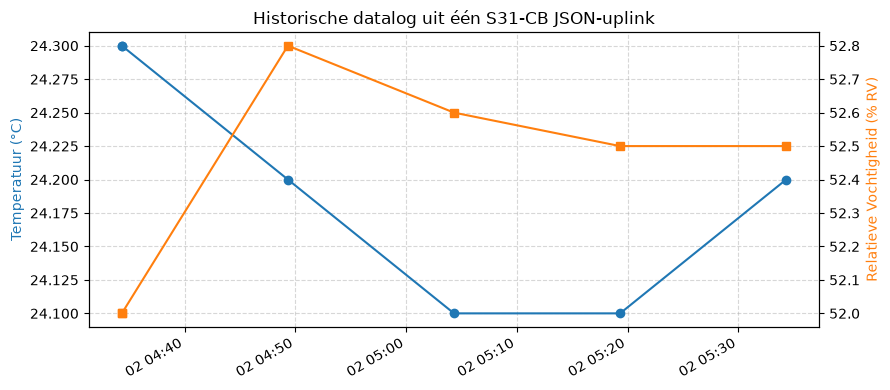

In [15]:
import matplotlib.pyplot as plt  # Importeer de grafieken-bibliotheek

# Maak een figuur aan met een specifieke afmeting
fig, ax1 = plt.subplots(figsize=(9, 4))

# Teken de temperatuur-grafiek op de linker Y-as (blauw)
ax1.plot(df_historiek["tijd"], df_historiek["temperatuur_C"], marker="o", color="tab:blue", label="Temperatuur (°C)")
ax1.set_ylabel("Temperatuur (°C)", color="tab:blue")
ax1.grid(True, linestyle="--", alpha=0.5)

# Maak een tweede Y-as aan die de X-as deelt (rechterzijde)
ax2 = ax1.twinx()
ax2.plot(df_historiek["tijd"], df_historiek["RV_pct"], marker="s", color="tab:orange", label="Relatieve Vochtigheid (%)")
ax2.set_ylabel("Relatieve Vochtigheid (% RV)", color="tab:orange")

plt.title("Historische datalog uit één S31-CB JSON-uplink")
fig.autofmt_xdate()  # Schuinzetten van datum-etiketten voor betere leesbaarheid
plt.tight_layout()
plt.show()

### Opdracht 4.1 · AT-commando's voor MQTT
Welke AT-commando's zou je naar de S31-CB sturen om elke 10 minuten via MQTT een JSON-bericht te publiceren op `broker.hivemq.com`, topic `ugent/i700301/stal/afdeling3`? Schrijf ze uit (zie de lijst in §4; de exacte syntaxis staat in §3.3 van de handleiding).

In [16]:
# ==============================================================================
# OPDRACHT 4.1: AT-COMMANDO'S VOOR MQTT & HIVEMQ CONFIGUREEREN
# INSTRUCTIES & HINTS FOR DE STUDENT:
# ==============================================================================
# Stel de reeks AT-commando's samen om de S31-CB (NB-IoT/MQTT) in te stellen:
# - Protocol & Modus : AT+PRO=3,5 (MQTT via TCP)
# - Serveradres      : AT+SERVADDR=broker.hivemq.com,1883
# - Client ID        : AT+CLIENT=s31cb-afdeling3
# - Publicatie Topic : AT+PUBTOPIC=ugent/i700301/stal/afdeling3
# - Quality of Serv. : AT+MQOS=1
# - Zendinterval     : AT+TDC=600 (10 minuten = 600 seconden)
# ==============================================================================

# SCHRIJF HIER JE AT-COMMANDO'S (BIJV. ALS EEN LIJST STRINGS):
at_commandos_s31cb = [
    # "AT+PRO=3,5",
    # "AT+SERVADDR=broker.hivemq.com,1883",
    # ...
]

# Un-comment om af te drukken:
# for cmd in at_commandos_s31cb:
#     print(cmd)


### Opdracht 4.2 · Netwerkbeperkingen: LoRaWAN vs NB-IoT
De LoRaWAN-versie stuurt 11 bytes, de NB-IoT-versie in JSON-modus enkele honderden bytes. Geef twee redenen waarom LoRaWAN zo zuinig *moet* zijn en NB-IoT dat niet hoeft.

In [17]:
# ==============================================================================
# OPDRACHT 4.2: LORAWAN VS NB-IOT NETWERKBEPERKINGEN
# INSTRUCTIES & HINTS FOR DE STUDENT:
# ==============================================================================
# Geef twee fundamentele redenen voor het verschil in payload-grootte:
# 1. Wettelijke regels & Netwerkcapaciteit op 868 MHz (Duty cycle 1%, Fair-Use Policy van TTN).
# 2. Energieverbruik & Kostenmodel (Batterijduur in ongelicentieerd spectrum vs. gelicentieerd 4G/5G-netwerk).
# ==============================================================================

# SCHRIJF HIER JE ANTWOORD:
reden_1_duty_cycle = ""
reden_2_energie_en_kosten = ""

# Un-comment om af te drukken:
# print(f"Reden 1 (Duty cycle & Spectrum): {reden_1_duty_cycle}")
# print(f"Reden 2 (Energie & Verdienmodel): {reden_2_energie_en_kosten}")


<details>
<summary><b>Oplossing tonen</b></summary>

**4.1**
```
AT+PRO=3,5
AT+SERVADDR=broker.hivemq.com,1883
AT+CLIENT=s31cb-afdeling3
AT+PUBTOPIC=ugent/i700301/stal/afdeling3
AT+MQOS=1
AT+TDC=600
AT+APN=<apn van de operator>
```
Geen `AT+UNAME`/`AT+PWD`: de publieke broker vraagt geen aanmelding. Bij een eigen broker wel, plus `AT+TLSMOD` voor versleuteling.

**4.2** (1) Op 868 MHz geldt een wettelijke *duty cycle* van 1 %: hoogstens 36 s zendtijd per uur, en met 0,3–50 kbit/s kost elke byte veel zendtijd; TTN hanteert bovendien een fair-use-beleid van 30 s uplink per dag. (2) Zenden kost energie: 11 bytes = milliseconden, dus jaren op één batterij. NB-IoT gebruikt gelicentieerd spectrum zonder duty cycle, haalt tientallen kbit/s, en je betaalt per simkaart per maand (binnen een bundel), niet per byte: 300 bytes JSON zijn dan geen probleem, al kost het wel meer batterij.

</details>

## Overzicht: Verbindingstypes en Protocollen

In dit notebook hebben we de volledige keten van industriële draadloze sensoren doorlopen. Hieronder vind je een samenvattend overzicht van de toegepaste technologieën:

| Onderwerp | Wat je in dit notebook concreet zag |
|---|---|
| **Draadloze Verbindingstypes** | **LoRaWAN** (S31-LB, energiezuinig, lange afstand via gateway) · **Bluetooth (BLE)** (lokale configuratie) · **NB-IoT / LTE-M** (S31-CB, rechtstreeks via 4G gsm-masten) |
| **Gegevensprotocollen** | **MQTT** (Publish-Subscribe via broker) · **CoAP / UDP / TCP** (instelbaar via AT-commando's) · **JSON vs Binaire Hex-bytes** |
| **Datadecoderingsketen** | Binaire bytes opvangen → Bitmasking & Big-Endian omzetting → JavaScript/Python decoders → Gestructureerde data in tabellen en grafieken |

Je bent nu klaar om door te gaan naar **`02_mqtt_live_meekijken.ipynb`**!